<a href="https://colab.research.google.com/github/svv1313/ml-math/blob/main/notebooks/regression_in_pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import matplotlib.pyplot as plt

In [ ]:
x = torch.tensor([0, 1, 2, 3, 4, 5, 6, 7.]) # E.g.: Dosage of drug for treating Alzheimer's disease
x

tensor([0., 1., 2., 3., 4., 5., 6., 7.])

In [ ]:
y = torch.tensor([1.86, 1.31, .62, .33, .09, -.67, -1.23, -1.37]) # E.g.: Patient's "forgetfulness score"
y

tensor([ 1.8600,  1.3100,  0.6200,  0.3300,  0.0900, -0.6700, -1.2300, -1.3700])

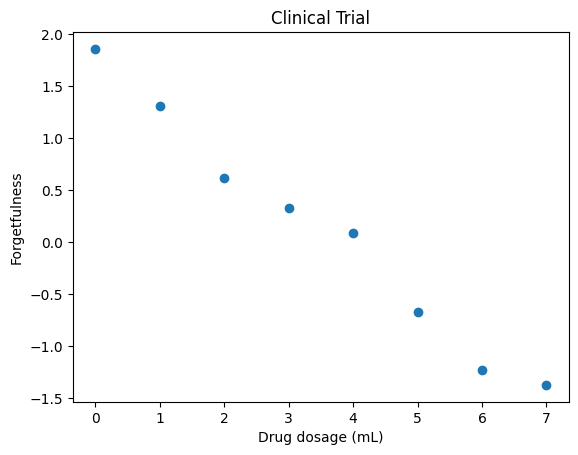

In [ ]:
fig, ax = plt.subplots()
plt.title("Clinical Trial")
plt.xlabel("Drug dosage (mL)")
plt.ylabel("Forgetfulness")
_ = ax.scatter(x, y)

In [ ]:
m = torch.tensor([0.9]).requires_grad_()
m

tensor([0.9000], requires_grad=True)

In [ ]:
b = torch.tensor([0.1]).requires_grad_()
b

tensor([0.1000], requires_grad=True)

In [ ]:
def regression(my_x, my_m, my_b):
    return my_m*my_x + my_b

In [ ]:
def regression_plot(my_x, my_y, my_m, my_b):

    fig, ax = plt.subplots()

    ax.scatter(my_x, my_y)

    x_min, x_max = ax.get_xlim()
    y_min = regression(x_min, my_m, my_b).detach().item()
    y_max = regression(x_max, my_m, my_b).detach().item()

    ax.set_xlim([x_min, x_max])
    _ = ax.plot([x_min, x_max], [y_min, y_max])

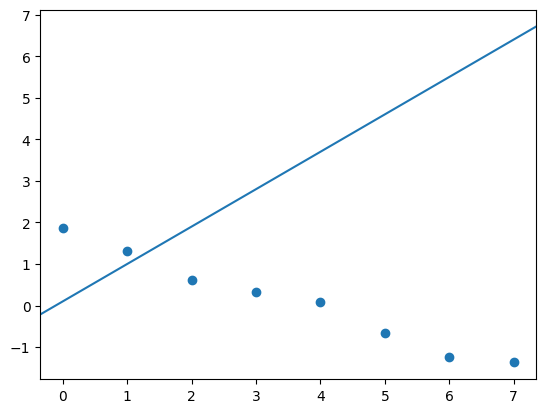

In [ ]:
regression_plot(x, y, m, b)

In [ ]:
yhat = regression(x, m, b)
yhat

tensor([0.1000, 1.0000, 1.9000, 2.8000, 3.7000, 4.6000, 5.5000, 6.4000],
       grad_fn=<AddBackward0>)

In [ ]:
def mse(my_yhat, my_y):
  sigma = torch.sum((my_yhat - my_y)**2)
  return sigma/len(my_y)

In [ ]:
C = mse(yhat, y)
C

tensor(19.6755, grad_fn=<DivBackward0>)

In [ ]:
C.backward()
C

tensor(19.6755, grad_fn=<DivBackward0>)

In [ ]:
m.grad

tensor([36.3050])

In [ ]:
b.grad

tensor([6.2650])

In [ ]:
optimizer = torch.optim.SGD([m, b], lr=0.01)
optimizer

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)

In [ ]:
optimizer.step()

In [ ]:
m

tensor([0.5369], requires_grad=True)

In [ ]:
b

tensor([0.0374], requires_grad=True)

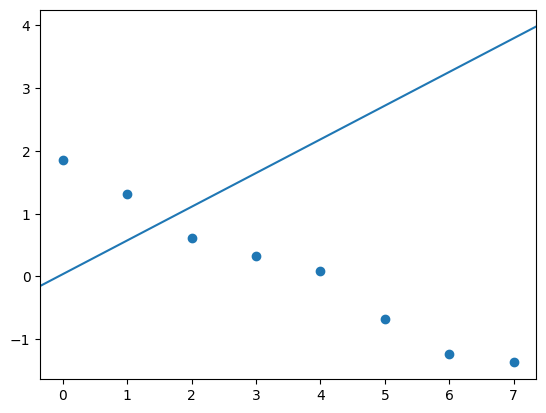

In [ ]:
regression_plot(x, y, m, b)

In [ ]:
C = mse(regression(x, m, b), y)
C

tensor(8.5722, grad_fn=<DivBackward0>)

In [ ]:
epoch = 1000
for round in range(epoch):
  optimizer.zero_grad()
  yhat = regression(x, m, b)
  C = mse(yhat, y)
  C.backward()
  optimizer.step()
  print(f"Epoch: {round}, Loss: {C}")

Epoch: 0, Loss: 0.9362916350364685
Epoch: 1, Loss: 0.9252382516860962
Epoch: 2, Loss: 0.9146171808242798
Epoch: 3, Loss: 0.904241144657135
Epoch: 4, Loss: 0.8940345048904419
Epoch: 5, Loss: 0.8839651346206665
Epoch: 6, Loss: 0.8740199208259583
Epoch: 7, Loss: 0.8641921281814575
Epoch: 8, Loss: 0.8544788360595703
Epoch: 9, Loss: 0.8448775410652161
Epoch: 10, Loss: 0.8353869915008545
Epoch: 11, Loss: 0.826005756855011
Epoch: 12, Loss: 0.8167323470115662
Epoch: 13, Loss: 0.807565450668335
Epoch: 14, Loss: 0.7985040545463562
Epoch: 15, Loss: 0.7895468473434448
Epoch: 16, Loss: 0.7806925177574158
Epoch: 17, Loss: 0.7719401121139526
Epoch: 18, Loss: 0.7632883787155151
Epoch: 19, Loss: 0.7547361254692078
Epoch: 20, Loss: 0.7462820410728455
Epoch: 21, Loss: 0.7379252314567566
Epoch: 22, Loss: 0.7296645641326904
Epoch: 23, Loss: 0.7214989066123962
Epoch: 24, Loss: 0.7134270668029785
Epoch: 25, Loss: 0.7054480910301208
Epoch: 26, Loss: 0.6975607872009277
Epoch: 27, Loss: 0.6897642016410828
Epoch

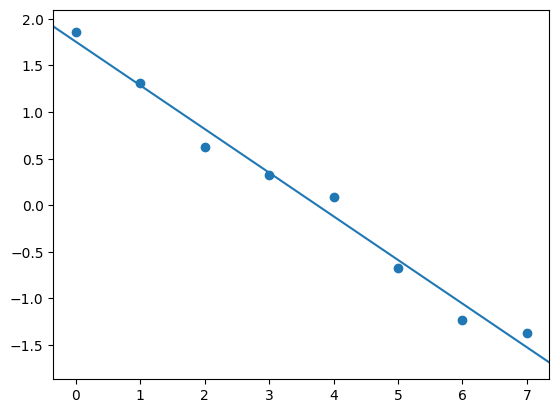

In [ ]:
regression_plot(x, y, m, b)

In [ ]:
m.item()

-0.468190997838974

In [ ]:
b.item()

1.754616618156433